# all necessary libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import RobustScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

import warnings
warnings.filterwarnings('ignore')

In [2]:
# Given files
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/mlp-term-3-2025-kaggle-assignment-2/sample_submission.csv
/kaggle/input/mlp-term-3-2025-kaggle-assignment-2/train.csv
/kaggle/input/mlp-term-3-2025-kaggle-assignment-2/test.csv


In [3]:
train_df = pd.read_csv('/kaggle/input/mlp-term-3-2025-kaggle-assignment-2/train.csv')
test_df = pd.read_csv('/kaggle/input/mlp-term-3-2025-kaggle-assignment-2/test.csv')
sample_submission = pd.read_csv('/kaggle/input/mlp-term-3-2025-kaggle-assignment-2/sample_submission.csv')

This block loads the training, testing, and sample submission datasets into pandas DataFrames, setting the stage for data analysis and modeling.
- `train_df`: Training data
- `test_df`: Testing data
- `sample_submission`: Format template for submission


# Rubics-1:Data types of different columns
Insights:
- Shows the number of rows and columns in the training dataset and the test dataset.
- Displays types such as integers, floats, and objects (categorical/text).
- Helps confirm appropriate data types before preprocessing.
- Facilitates targeted handling of numerical vs categorical features in subsequent analysis.


In [4]:
print("Train dataset shape:", train_df.shape)
print("Test dataset shape:", test_df.shape)

Train dataset shape: (29500, 14)
Test dataset shape: (7000, 13)


In [5]:
print("\nData types of columns:")
print(train_df.dtypes)


Data types of columns:
id                  int64
adults              int64
children            int64
weekends            int64
weekdays            int64
meal_type          object
room_type          object
arrival            object
lead_time         float64
segment            object
repeat              int64
price             float64
requests            int64
booking_status      int64
dtype: object


# Rubics-2:Descriptive statistics of numerical columns
This block generates descriptive statistics for all numerical columns in the training dataset using `pandas.DataFrame.describe()`. 
Key insights include:
- Count of non-null values indicating data completeness.
- Mean and median (50%) showing central tendency.
- Standard deviation reflecting data dispersion.
- Min, max, and quartiles (25%, 75%) indicating spread and potential outliers.
  
This summary provides a foundational understanding of the data distribution and variability, essential for preprocessing and modeling decisions.


In [6]:
print("\nDescriptive statistics for numerical columns:")
numerical_cols = train_df.select_dtypes(include=[np.number]).columns
print(train_df[numerical_cols].describe())


Descriptive statistics for numerical columns:
                 id        adults      children      weekends      weekdays  \
count  29500.000000  29500.000000  29500.000000  29500.000000  29500.000000   
mean   14749.500000      1.843559      0.106576      0.808136      2.202237   
std     8516.060807      0.518711      0.405517      0.868835      1.404200   
min        0.000000      0.000000      0.000000      0.000000      0.000000   
25%     7374.750000      2.000000      0.000000      0.000000      1.000000   
50%    14749.500000      2.000000      0.000000      1.000000      2.000000   
75%    22124.250000      2.000000      0.000000      2.000000      3.000000   
max    29499.000000      4.000000     10.000000      6.000000     17.000000   

          lead_time        repeat         price      requests  booking_status  
count  27805.000000  29500.000000  27917.000000  29500.000000    29500.000000  
mean      85.405431      0.026000    103.483304      0.619661        0.326441  
s

# Rubics-3: Identify and handle the missing values

In [7]:
print("\nMissing values in train dataset:")
missing_train = train_df.isnull().sum()
if missing_train[missing_train > 0].empty:
    print("No missing values in train dataset.")
else:
    print(missing_train[missing_train > 0])

print("\nMissing values in test dataset:")
missing_test = test_df.isnull().sum()
if missing_test[missing_test > 0].empty:
    print("No missing values in test dataset.")
else:
    print(missing_test[missing_test > 0])



Missing values in train dataset:
room_type     841
lead_time    1695
price        1583
dtype: int64

Missing values in test dataset:
room_type    1660
lead_time     412
price         406
dtype: int64


This block checks for missing values in the train and test datasets:

- It calculates the total number of missing values per column.
- It prints details only for columns that have missing data.
- If no missing values are present, it handles the situation gracefully without errors.

Imputation of missing values is performed later in the workflow, using strategies like median for numerical features and most frequent for categorical features, ensuring data completeness for modeling.


# Rubics-4:Identifying and Handling the duplicates

In [8]:
print("\nDuplicates in train dataset:", train_df.duplicated().sum())
print("Duplicates in test dataset:", test_df.duplicated().sum())


Duplicates in train dataset: 0
Duplicates in test dataset: 0


**INSIGHT:**
- The number of duplicate rows is counted and printed for both datasets.
- Identifying duplicates ensures data quality by confirming dataset uniqueness.
- If duplicates exist, they can bias models and lead to overfitting, so detecting them is critical.
- The duplicate check confirms that there are no duplicate rows in both the training and test datasets, ensuring data integrity and preventing potential modeling biases.



# Rubics-5:Identifying and Handling outliers
This block performs outlier detection on key numerical columns using the Interquartile Range (IQR) method:

- Outliers are counted in columns like adults, children, weekends, weekdays, lead_time, price, and requests.
- The presence of several outliers is confirmed across these features.
- The decision to retain outliers is justified, acknowledging they likely represent valid booking scenarios rather than errors.
  
This approach balances statistical detection with domain understanding, preserving important data variability for modeling.

In [9]:
print("\nOutlier analysis using IQR method:")
for col in ['adults', 'children', 'weekends', 'weekdays', 'lead_time', 'price', 'requests']:
    Q1 = train_df[col].quantile(0.25)
    Q3 = train_df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = ((train_df[col] < lower_bound) | (train_df[col] > upper_bound)).sum()
    print(f"{col}: {outliers} outliers detected")
print("Retaining as they may represent valid bookings")


Outlier analysis using IQR method:
adults: 8263 outliers detected
children: 2227 outliers detected
weekends: 14 outliers detected
weekdays: 252 outliers detected
lead_time: 905 outliers detected
price: 1336 outliers detected
requests: 617 outliers detected
Retaining as they may represent valid bookings


# Rubics-6: Visualizations and insights

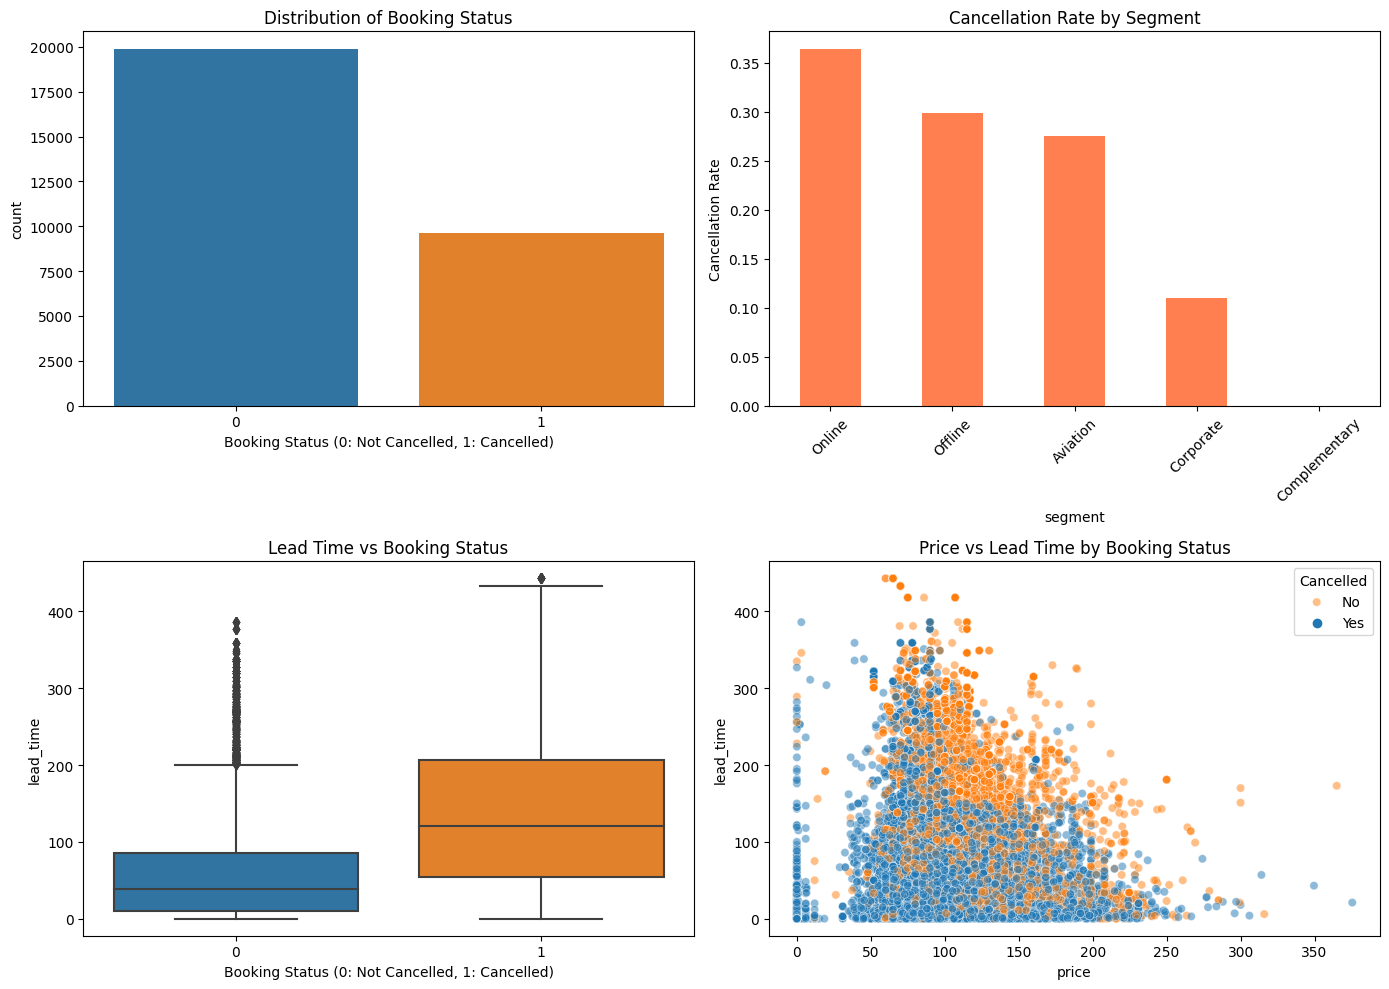

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(data=train_df, x='booking_status', ax=axes[0, 0])
axes[0, 0].set_title('Distribution of Booking Status')
axes[0, 0].set_xlabel('Booking Status (0: Not Cancelled, 1: Cancelled)')

cancel_by_segment = train_df.groupby('segment')['booking_status'].mean().sort_values(ascending=False)
cancel_by_segment.plot(kind='bar', ax=axes[0, 1], color='coral')
axes[0, 1].set_title('Cancellation Rate by Segment')
axes[0, 1].set_ylabel('Cancellation Rate')
axes[0, 1].tick_params(axis='x', rotation=45)

sns.boxplot(data=train_df, x='booking_status', y='lead_time', ax=axes[1, 0])
axes[1, 0].set_title('Lead Time vs Booking Status')
axes[1, 0].set_xlabel('Booking Status (0: Not Cancelled, 1: Cancelled)')

sns.scatterplot(data=train_df, x='price', y='lead_time', hue='booking_status', alpha=0.5, ax=axes[1, 1])
axes[1, 1].set_title('Price vs Lead Time by Booking Status')
axes[1, 1].legend(title='Cancelled', labels=['No', 'Yes'])

plt.tight_layout()
plt.show()

This block presents four visualizations revealing key insights from the dataset:

- **Booking Status Distribution**: Shows the balance between cancelled and not cancelled bookings, essential for understanding class distribution.
- **Cancellation Rate by Segment**: Highlights which customer segments have higher cancellation tendencies, helping target risk groups.
- **Lead Time vs Booking Status**: Boxplot indicates that cancelled bookings tend to have longer lead times, suggesting early cancellations.
- **Price vs Lead Time by Booking Status**: Scatterplot visualizes relationships among price, lead time, and cancellations, indicating possible correlations affecting booking behavior.

These visualizations provide critical exploratory insights to inform feature engineering and modeling strategies.


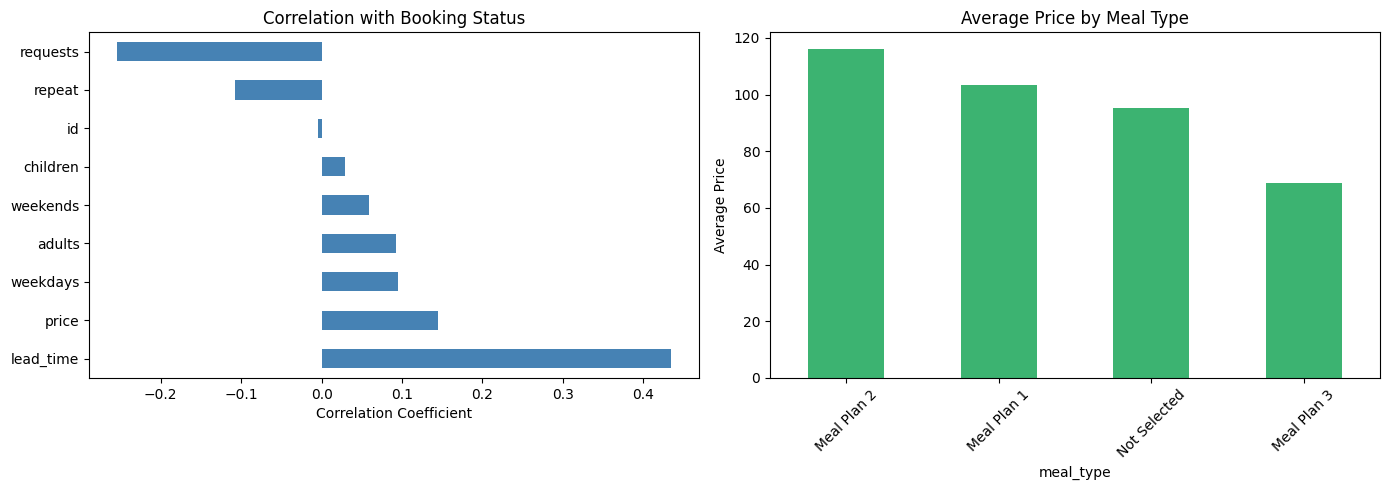

In [11]:
numeric_cols_for_corr = train_df.select_dtypes(include=[np.number]).columns
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

corr_with_target = train_df[numeric_cols_for_corr].corr()['booking_status'].sort_values(ascending=False)
corr_with_target = corr_with_target[corr_with_target.index != 'booking_status']
corr_with_target.plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Correlation with Booking Status')
axes[0].set_xlabel('Correlation Coefficient')

avg_price_by_meal = train_df.groupby('meal_type')['price'].mean().sort_values(ascending=False)
avg_price_by_meal.plot(kind='bar', ax=axes[1], color='mediumseagreen')
axes[1].set_title('Average Price by Meal Type')
axes[1].set_ylabel('Average Price')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

This block presents two visual analyses focused on relationships in the data:

- **Correlation with Booking Status**: Displays numeric features ranked by their correlation with cancellations, highlighting which variables most influence the target.
- **Average Price by Meal Type**: Shows price differences across meal categories, revealing how meal choices may impact booking prices.

These insights help prioritize features for modeling and understand pricing patterns related to customer choices.


# Rubics-7: Scaling Numerical Features and Encode categorical Features
This block details comprehensive data preprocessing steps:

- Dropping irrelevant columns (`id`, `arrival`) from train and test sets.
- Separating features (`X`) and target (`y`).
- Handling missing values:
  - Numerical: imputed with median
  - Categorical: imputed with most frequent
- Confirming all missing values are addressed
- Encoding categorical variables with LabelEncoder
- Scaling features with RobustScaler to handle outliers
- Wrapping transformed data back into DataFrames with original feature labels
- Displaying data types, sample statistics, and feature samples post-processing

This ensures data quality, proper encoding, and scaling for robust modeling.


In [12]:
train_df.drop(['id', 'arrival'], axis=1, inplace=True)
test_ids = test_df['id']
test_df.drop(['id', 'arrival'], axis=1, inplace=True)

X = train_df.drop('booking_status', axis=1)
y = train_df['booking_status']

categorical_cols = ['meal_type', 'room_type', 'segment']
numerical_cols = ['adults', 'children', 'weekends', 'weekdays', 'lead_time', 'price', 'requests', 'repeat']

num_imputer = SimpleImputer(strategy='median')
X[numerical_cols] = num_imputer.fit_transform(X[numerical_cols])
test_df[numerical_cols] = num_imputer.transform(test_df[numerical_cols])

cat_imputer = SimpleImputer(strategy='most_frequent')
X[categorical_cols] = cat_imputer.fit_transform(X[categorical_cols])
test_df[categorical_cols] = cat_imputer.transform(test_df[categorical_cols])

print("\nAfter imputation - Missing values in X:", X.isnull().sum().sum())
print("After imputation - Missing values in test:", test_df.isnull().sum().sum())

label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))
    test_df[col] = le.transform(test_df[col].astype(str))
    label_encoders[col] = le

print("\nAfter encoding - Data types:")
print(X.dtypes)

scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)
test_scaled = scaler.transform(test_df)

X = pd.DataFrame(X_scaled, columns=X.columns, index=X.index)
test_df = pd.DataFrame(test_scaled, columns=test_df.columns, index=test_df.index)

print("\nAfter scaling with RobustScaler - Sample statistics:")
print(X.describe())

print("\nFeatures after preprocessing:")
print(X.head())


After imputation - Missing values in X: 0
After imputation - Missing values in test: 0

After encoding - Data types:
adults       float64
children     float64
weekends     float64
weekdays     float64
meal_type      int64
room_type      int64
lead_time    float64
segment        int64
repeat       float64
price        float64
requests     float64
dtype: object

After scaling with RobustScaler - Sample statistics:
             adults      children      weekends      weekdays     meal_type  \
count  29500.000000  29500.000000  29500.000000  29500.000000  29500.000000   
mean      -0.156441      0.106576     -0.095932      0.101119      0.513525   
std        0.518711      0.405517      0.434418      0.702100      1.045259   
min       -2.000000      0.000000     -0.500000     -1.000000      0.000000   
25%        0.000000      0.000000     -0.500000     -0.500000      0.000000   
50%        0.000000      0.000000      0.000000      0.000000      0.000000   
75%        0.000000      0.000

# Rubics-8: Model Building
**The following models are trained:**
- Logistic Regression
- Linear Regression
- Decision Tree Classifier
- Random Forest Classifier
- Gradient Boosting Classifier
- XGBoost Classifier
- SVM
- K Nearest Neighbors
- Naive Bayes
- AdaBoost 

This block performs model training and evaluation on a validation set:

- Splits data into training (80%) and validation (20%) sets with stratification on the target.
- Trains 10 different models including Logistic Regression, Linear Regression (converted to classification), decision trees, ensemble methods, SVM, KNN, Naive Bayes, and AdaBoost.
- Predicts labels and probabilities for validation data.
- Calculates and prints key metrics: accuracy and ROC-AUC for each model.
- Stores model performance and trained models for further analysis.

This systematic approach enables comprehensive performance comparison across diverse algorithms.


In [13]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("\nTraining set size:", X_train.shape)
print("Validation set size:", X_val.shape)
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000, n_jobs=-1),
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss', n_jobs=-1),
    'SVM': SVC(random_state=42, probability=True),
    'KNN': KNeighborsClassifier(n_jobs=-1),
    'Naive Bayes': GaussianNB(),
    'AdaBoost': AdaBoostClassifier(random_state=42)
}

results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    
    if name == 'Linear Regression':
        y_pred_continuous = model.predict(X_val)
        y_pred = (y_pred_continuous >= 0.5).astype(int)
        y_pred_proba = np.clip(y_pred_continuous, 0, 1)
    else:
        y_pred = model.predict(X_val)
        y_pred_proba = model.predict_proba(X_val)[:, 1]
    
    accuracy = accuracy_score(y_val, y_pred)
    roc_auc = roc_auc_score(y_val, y_pred_proba)
    
    results[name] = {
        'accuracy': accuracy,
        'roc_auc': roc_auc,
        'model': model
    }
    
    print(f"\n{name}:")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"ROC-AUC: {roc_auc:.4f}")



Training set size: (23600, 11)
Validation set size: (5900, 11)

Logistic Regression:
Accuracy: 0.8005
ROC-AUC: 0.8478

Linear Regression:
Accuracy: 0.7807
ROC-AUC: 0.8413

Decision Tree:
Accuracy: 0.8400
ROC-AUC: 0.8220

Random Forest:
Accuracy: 0.8775
ROC-AUC: 0.9324

Gradient Boosting:
Accuracy: 0.8461
ROC-AUC: 0.8952

XGBoost:
Accuracy: 0.8714
ROC-AUC: 0.9266

SVM:
Accuracy: 0.8242
ROC-AUC: 0.8727

KNN:
Accuracy: 0.8402
ROC-AUC: 0.8873

Naive Bayes:
Accuracy: 0.6186
ROC-AUC: 0.8098

AdaBoost:
Accuracy: 0.8088
ROC-AUC: 0.8685


# Rubics-9: Hyperparameter Tuning on any 3 of the models
- Random Forest Hyperparameter Tuning
- Gradient Boosting Hyperparameter Tuning
- XGBoost Hyperparameter Tuning

## Random Forest Hyperparameter Tuning
This block performs hyperparameter tuning for the Random Forest model using GridSearchCV:

- Defines a parameter grid with variations in number of trees (`n_estimators`), tree depth, minimum samples for splits and leaves, and maximum features.
- Runs 3-fold cross-validation optimizing for ROC-AUC score across parameter combinations.
- Prints the best combination of parameters found.
- Evaluates the tuned model on the validation set, reporting accuracy and ROC-AUC.

This tuning enhances the model’s predictive performance by systematically optimizing key parameters.

In [14]:
param_grid_rf = {
    'n_estimators': [200, 300],
    'max_depth': [15, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt']
}

grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid_rf,
    cv=3,
    scoring='roc_auc',
    n_jobs=-1
)
grid_rf.fit(X_train, y_train)

print("\nRandom Forest - Best parameters:", grid_rf.best_params_)
print("Random Forest - Best ROC-AUC:", grid_rf.best_score_)

y_pred_rf = grid_rf.predict(X_val)
y_pred_proba_rf = grid_rf.predict_proba(X_val)[:, 1]
print("Random Forest Tuned - Validation Accuracy:", accuracy_score(y_val, y_pred_rf))
print("Random Forest Tuned - Validation ROC-AUC:", roc_auc_score(y_val, y_pred_proba_rf))



Random Forest - Best parameters: {'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}
Random Forest - Best ROC-AUC: 0.9240390468392015
Random Forest Tuned - Validation Accuracy: 0.8762711864406779
Random Forest Tuned - Validation ROC-AUC: 0.9335604847918532


In [15]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, classification_report

param_grid_rf = {
    'n_estimators': [100, 200, 300, 400],
    'max_depth': [10, 15, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', 'auto']
}

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid_rf,
    cv=cv_strategy,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

grid_rf.fit(X_train, y_train)

print("\nRandom Forest - Best parameters:", grid_rf.best_params_)
print("Random Forest - Best ROC-AUC:", grid_rf.best_score_)

y_pred_rf = grid_rf.predict(X_val)
y_pred_proba_rf = grid_rf.predict_proba(X_val)[:, 1]

print("Validation Accuracy:", accuracy_score(y_val, y_pred_rf))
print("Validation ROC-AUC:", roc_auc_score(y_val, y_pred_proba_rf))
print("Validation F1 Score:", f1_score(y_val, y_pred_rf))
print("\nClassification Report:\n", classification_report(y_val, y_pred_rf))

Fitting 5 folds for each of 432 candidates, totalling 2160 fits


/usr/local/lib/python3.11/dist-packages/sklearn/ensemble/_forest.py:424: FutureWarning: `max_features='auto'` has been deprecated in 1.1 and will be removed in 1.3. To keep the past behaviour, explicitly set `max_features='sqrt'` or remove this parameter as it is also the default value for RandomForestClassifiers and ExtraTreesClassifiers.
  warn(
/usr/local/lib/python3.11/dist-packages/sklearn/ensemble/_forest.py:424: FutureWarning: `max_features='auto'` has been deprecated in 1.1 and will be removed in 1.3. To keep the past behaviour, explicitly set `max_features='sqrt'` or remove this parameter as it is also the default value for RandomForestClassifiers and ExtraTreesClassifiers.
  warn(
/usr/local/lib/python3.11/dist-packages/sklearn/ensemble/_forest.py:424: FutureWarning: `max_features='auto'` has been deprecated in 1.1 and will be removed in 1.3. To keep the past behaviour, explicitly set `max_features='sqrt'` or remove this parameter as it is also the default value for RandomFor


Random Forest - Best parameters: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 400}
Random Forest - Best ROC-AUC: 0.9277819993894305
Validation Accuracy: 0.8842372881355932
Validation ROC-AUC: 0.9359422042863241
Validation F1 Score: 0.8143517260125034

Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.94      0.92      3974
           1       0.85      0.78      0.81      1926

    accuracy                           0.88      5900
   macro avg       0.88      0.86      0.87      5900
weighted avg       0.88      0.88      0.88      5900



## Gradient Boosting Hyperparameter Tuning
This block performs hyperparameter tuning for the Gradient Boosting model using GridSearchCV:

- Parameter grid includes tree count (`n_estimators`), learning rate, tree depth, subsample ratio, and minimum samples to split nodes.
- Uses 3-fold cross-validation optimizing ROC-AUC to find the best parameters.
- Prints the optimal parameter set and best ROC-AUC during tuning.
- Evaluates the tuned model’s accuracy and ROC-AUC on the validation set.

This tuning refines the Gradient Boosting model to maximize predictive accuracy and robustness.


In [16]:
param_grid_gb = {
    'n_estimators': [200, 300],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 5],
    'subsample': [0.9, 1.0],
    'min_samples_split': [2, 5]
}

grid_gb = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    param_grid_gb,
    cv=3,
    scoring='roc_auc',
    n_jobs=-1
)
grid_gb.fit(X_train, y_train)

print("\nGradient Boosting - Best parameters:", grid_gb.best_params_)
print("Gradient Boosting - Best ROC-AUC:", grid_gb.best_score_)

y_pred_gb = grid_gb.predict(X_val)
y_pred_proba_gb = grid_gb.predict_proba(X_val)[:, 1]
print("Gradient Boosting Tuned - Validation Accuracy:", accuracy_score(y_val, y_pred_gb))
print("Gradient Boosting Tuned - Validation ROC-AUC:", roc_auc_score(y_val, y_pred_proba_gb))



Gradient Boosting - Best parameters: {'learning_rate': 0.1, 'max_depth': 5, 'min_samples_split': 5, 'n_estimators': 300, 'subsample': 0.9}
Gradient Boosting - Best ROC-AUC: 0.9223211717309447
Gradient Boosting Tuned - Validation Accuracy: 0.8705084745762712
Gradient Boosting Tuned - Validation ROC-AUC: 0.9270531690672653


## XGBoost Hyperparameter Tuning
This block conducts hyperparameter tuning for the XGBoost model using GridSearchCV:

- The parameter grid explores tree count, learning rate, tree depth, subsample ratio, column sampling, and minimum child weight.
- Uses 3-fold cross-validation optimizing ROC-AUC to identify the best parameters.
- Prints the best parameter combination and ROC-AUC score from tuning.
- Evaluates the tuned XGBoost model’s accuracy and ROC-AUC on the validation set.

This method ensures optimized performance of XGBoost by systematically fine-tuning critical hyperparameters


In [17]:
param_grid_xgb = {
    'n_estimators': [200, 300],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 5],
    'subsample': [0.9, 1.0],
    'colsample_bytree': [0.9, 1.0],
    'min_child_weight': [1, 3]
}

grid_xgb = GridSearchCV(
    XGBClassifier(random_state=42, eval_metric='logloss', use_label_encoder=False, n_jobs=-1),
    param_grid_xgb,
    cv=3,
    scoring='roc_auc',
    n_jobs=-1
)
grid_xgb.fit(X_train, y_train)

print("\nXGBoost - Best parameters:", grid_xgb.best_params_)
print("XGBoost - Best ROC-AUC:", grid_xgb.best_score_)

y_pred_xgb = grid_xgb.predict(X_val)
y_pred_proba_xgb = grid_xgb.predict_proba(X_val)[:, 1]
print("XGBoost Tuned - Validation Accuracy:", accuracy_score(y_val, y_pred_xgb))
print("XGBoost Tuned - Validation ROC-AUC:", roc_auc_score(y_val, y_pred_proba_xgb))



XGBoost - Best parameters: {'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 5, 'min_child_weight': 1, 'n_estimators': 300, 'subsample': 0.9}
XGBoost - Best ROC-AUC: 0.9200409521644337
XGBoost Tuned - Validation Accuracy: 0.8686440677966102
XGBoost Tuned - Validation ROC-AUC: 0.9251014250990732


# Rubics-10: Comparison of model performances


Final Model Performance Comparison:
                      Model  Accuracy   ROC-AUC
10      Random Forest Tuned  0.884237  0.935942
3             Random Forest  0.877458  0.932360
11  Gradient Boosting Tuned  0.870508  0.927053
5                   XGBoost  0.871356  0.926566
12            XGBoost Tuned  0.868644  0.925101
4         Gradient Boosting  0.846102  0.895227
7                       KNN  0.840169  0.887347
6                       SVM  0.824237  0.872731
9                  AdaBoost  0.808814  0.868489
0       Logistic Regression  0.800508  0.847774
1         Linear Regression  0.780678  0.841341
2             Decision Tree  0.840000  0.822049
8               Naive Bayes  0.618644  0.809797


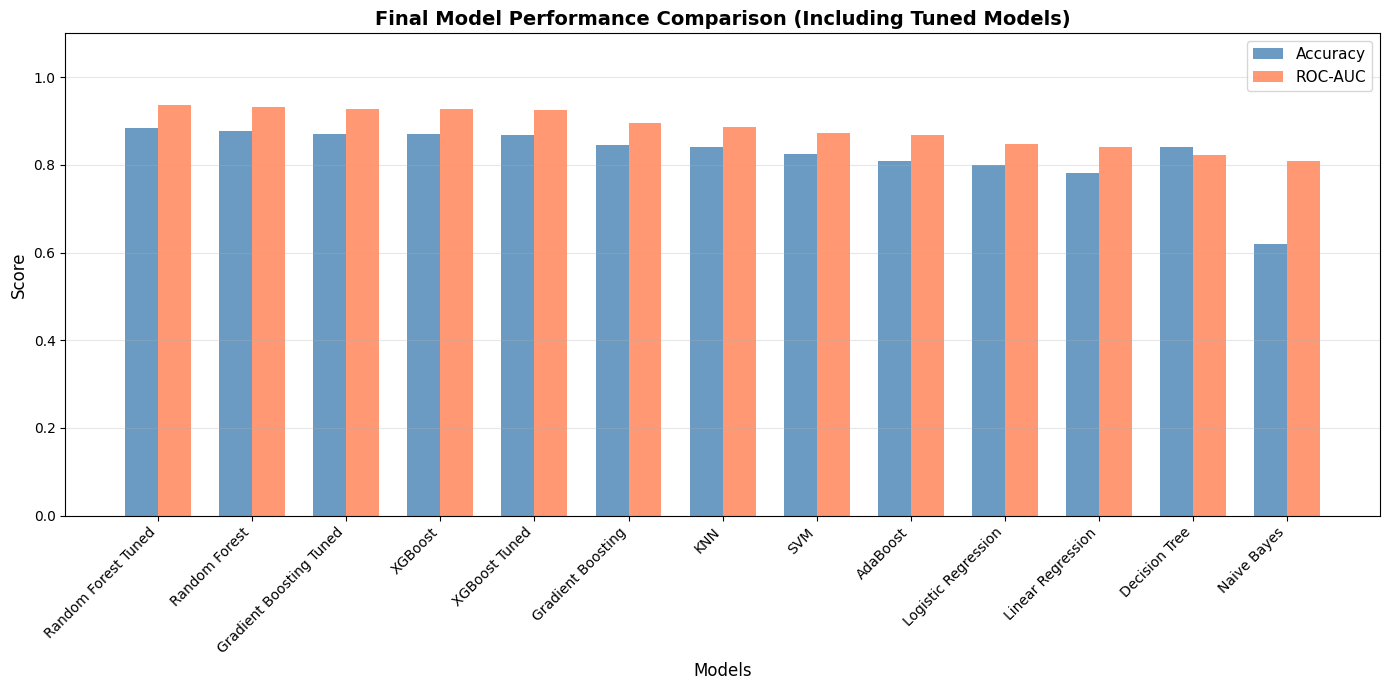


Best performing model: Random Forest Tuned
Best ROC-AUC Score: 0.9359


In [18]:
results['Random Forest Tuned'] = {
    'accuracy': accuracy_score(y_val, y_pred_rf),
    'roc_auc': roc_auc_score(y_val, y_pred_proba_rf)
}

results['Gradient Boosting Tuned'] = {
    'accuracy': accuracy_score(y_val, y_pred_gb),
    'roc_auc': roc_auc_score(y_val, y_pred_proba_gb)
}

results['XGBoost Tuned'] = {
    'accuracy': accuracy_score(y_val, y_pred_xgb),
    'roc_auc': roc_auc_score(y_val, y_pred_proba_xgb)
}

comparison_df = pd.DataFrame({
    'Model': list(results.keys()),
    'Accuracy': [results[model]['accuracy'] for model in results.keys()],
    'ROC-AUC': [results[model]['roc_auc'] for model in results.keys()]
})

comparison_df = comparison_df.sort_values('ROC-AUC', ascending=False)
print("\nFinal Model Performance Comparison:")
print(comparison_df)

plt.figure(figsize=(14, 7))
x = np.arange(len(comparison_df))
width = 0.35

bars1 = plt.bar(x - width/2, comparison_df['Accuracy'], width, label='Accuracy', alpha=0.8, color='steelblue')
bars2 = plt.bar(x + width/2, comparison_df['ROC-AUC'], width, label='ROC-AUC', alpha=0.8, color='coral')

plt.xlabel('Models', fontsize=12)
plt.ylabel('Score', fontsize=12)
plt.title('Final Model Performance Comparison (Including Tuned Models)', fontsize=14, fontweight='bold')
plt.xticks(x, comparison_df['Model'], rotation=45, ha='right')
plt.legend(fontsize=11)
plt.ylim(0, 1.1)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

best_model_name = comparison_df.iloc[0]['Model']
print(f"\nBest performing model: {best_model_name}")
print(f"Best ROC-AUC Score: {comparison_df.iloc[0]['ROC-AUC']:.4f}")

if 'XGBoost' in best_model_name:
    best_model = grid_xgb.best_estimator_
elif 'Gradient Boosting' in best_model_name:
    best_model = grid_gb.best_estimator_
elif 'Random Forest' in best_model_name:
    best_model = grid_rf.best_estimator_
else:
    best_model = results[best_model_name]['model']

test_predictions = best_model.predict(test_df)

This block provides a comprehensive comparison of all trained models including tuned versions:

- Stores accuracy and ROC-AUC scores for tuned Random Forest, Gradient Boosting, and XGBoost models in results dictionary.
- Compiles a DataFrame summarizing performance metrics across all models.
- Sorts models by ROC-AUC for clear ranking of predictive quality.
- Visualizes model performance side-by-side using bar charts for accuracy and ROC-AUC.
- Identifies and prints the best performing model based on ROC-AUC.
- Selects the best model instance accordingly.
- Generates predictions on the test dataset using the best model.

This end-to-end assessment highlights top model choices and prepares predictions for submission or further use.


# Final Submission
This final block creates the submission file:

- Combines test dataset IDs with predicted booking statuses from the best model into a DataFrame.
- Saves the DataFrame as `submission.csv` without row indices.
- Confirms creation of the submission file and previews the first few rows.

This prepares the predictions in the required format for evaluation or competition submission.


In [19]:
submission = pd.DataFrame({
    'id': test_ids,
    'booking_sta_tus': test_predictions
})

submission.to_csv('submission.csv', index=False)
print("\nSubmission file created successfully!")
print(submission.head())


Submission file created successfully!
   id  booking_sta_tus
0   0                0
1   1                0
2   2                0
3   3                1
4   4                0
